In [4]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split 
from sklearn.pipeline import Pipeline 
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression 
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, 
    f1_score, confusion_matrix, roc_auc_score, classification_report
) 
import joblib 
import os
print("leb done") 

leb done


In [11]:
data = pd.read_csv("/kaggle/input/datasets/gajnabi/spam-set/spam_dataset.csv")
print("data load",data)

print(data.columns) 
print(data.head())
print(data.shape)


data load           email_id                     sender                   subject  \
0      EMAIL000001         offers@example.com         You are a winner!   
1      EMAIL000002    student@college.example               Class notes   
2      EMAIL000003    student@college.example            Meeting update   
3      EMAIL000004    support@service.example  Appointment confirmation   
4      EMAIL000005          team@work.example  Appointment confirmation   
...            ...                        ...                       ...   
11922  EMAIL011923    support@service.example  Appointment confirmation   
11923  EMAIL011924    support@service.example  Appointment confirmation   
11924  EMAIL011925    student@college.example            Project update   
11925  EMAIL011926  colleague@company.example            Project update   
11926  EMAIL011927  colleague@company.example       Document for review   

                                              email_text     label  
0           Get a fr

# missing value 


In [7]:
print("missing value \n" , data.isnull().sum()) 

# duplicates 

print("duplicates \n" , data[data.duplicated()])  # duplicated ().sum() 

missing value 
 email_id       0
sender        91
subject       85
email_text    16
label          0
dtype: int64
duplicates 
 Empty DataFrame
Columns: [email_id, sender, subject, email_text, label]
Index: []


# **remove duplicate rows ****

In [8]:
df = data.drop_duplicates().copy()
print("remove duplicate \n" , df) 


remove duplicate 
           email_id                     sender                   subject  \
0      EMAIL000001         offers@example.com         You are a winner!   
1      EMAIL000002    student@college.example               Class notes   
2      EMAIL000003    student@college.example            Meeting update   
3      EMAIL000004    support@service.example  Appointment confirmation   
4      EMAIL000005          team@work.example  Appointment confirmation   
...            ...                        ...                       ...   
11922  EMAIL011923    support@service.example  Appointment confirmation   
11923  EMAIL011924    support@service.example  Appointment confirmation   
11924  EMAIL011925    student@college.example            Project update   
11925  EMAIL011926  colleague@company.example            Project update   
11926  EMAIL011927  colleague@company.example       Document for review   

                                              email_text     label  
0          

# Fill missing value 

In [9]:
df["sender"] = df["sender"].fillna("")
df["subject"] = df["subject"].fillna("")
df["email_text"] = df["email_text"].fillna("")
print("clean data \n", df.shape)
print("missing \n" , df.duplicated().sum()) 
print("null value \n " ,df.isnull().sum()) 

clean data 
 (11927, 5)
missing 
 0
null value 
  email_id      0
sender        0
subject       0
email_text    0
label         0
dtype: int64


# Target and features 

In [10]:
x = df["email_text"]         # features 
y = df["label"]              # target 
print(x.head())
print(y.value_counts()) 

0         Get a free phone by entering our prize draw.
1    Please review the document before Friday. Than...
2        Please let me know if you have any questions.
3       Happy birthday! Hope you have a wonderful day.
4    Hi, can we move our meeting to tomorrow aftern...
Name: email_text, dtype: object
label
spam        6131
not spam    5796
Name: count, dtype: int64


Vi****sulization****

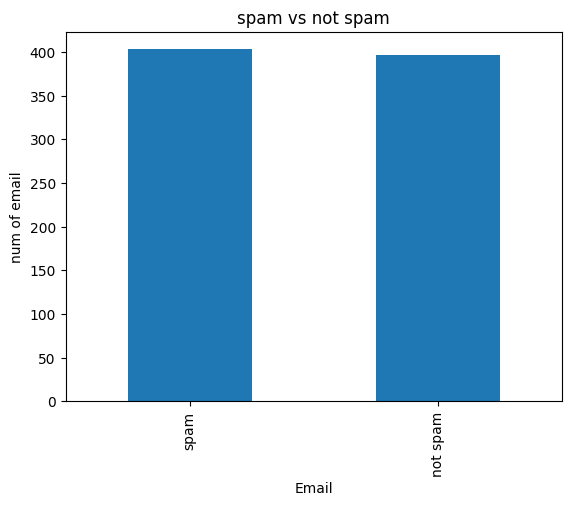

In [31]:
visual = y.value_counts() 
visual.plot(kind="bar") 
plt.title("spam vs not spam")
plt.xlabel("Email")
plt.ylabel("num of email") 
plt.show() 


** train test phase**********


In [32]:
x_train , x_test , y_train , y_test = train_test_split(
    x ,
    y ,
    test_size = 0.2, 
    random_state = 42, 
    stratify = y
)
print ("training sample: " , len(x_train))
print ("testing sample : " ,len(x_test)) 


model = Pipeline([
    ("text convert into numerical" , TfidfVectorizer()),
    ("classification model" , LogisticRegression(max_iter = 1000)) 
]) 

model.fit(x_train ,y_train) 


training sample: 640
testing sample :  160


Pipeline(steps=[('text convert into numerical', TfidfVectorizer()),
                ('classification model', LogisticRegression(max_iter=1000))])

In [33]:
y_prediction = model.predict(x_test) 
print("model pridiction ") 

print ("\n confussion matrix") 
print(confusion_matrix(y_test , y_prediction)) 

print("\n Prcision" , precision_score(y_test , y_prediction ,pos_label="spam", zero_division=0)*100 , "%") 
print("\n recall " , recall_score (y_test , y_prediction ,pos_label="spam", zero_division=0)*100,"%") 
print("\n f1-score" , f1_score(y_test , y_prediction ,pos_label="spam", zero_division=0)*100 , "%")
accuracy = accuracy_score(y_test , y_prediction) 
print("accuracy of model" , accuracy*100 , "%") 


model pridiction 

 confussion matrix
[[79  0]
 [ 2 79]]

 Prcision 100.0 %

 recall  97.53086419753086 %

 f1-score 98.75 %
accuracy of model 98.75 %


saving model 


In [34]:
joblib.dump(model, "spam___model.pkl")

print("Full file path:", os.path.abspath("spam_model.pkl"))
print("File exists:", os.path.exists("spam_model.pkl"))

new_email = input("\nEnter your email: ")
prediction = model.predict([new_email])

if prediction[0] == "spam":
    print("Result: Spam Email")
else:
    print("Result: Not Spam Email") 


Full file path: /kaggle/working/spam_model.ipynb
File exists: False



Enter your email:  Subject: Request for Leave  Dear Sir/Madam,  I hope you are doing well. I am writing to request leave for tomorrow due to some personal work. I will make sure to complete any pending tasks as soon as possible.  Thank you for your understanding.  Best regards, Harsh Pandey


Result: Not Spam Email
